In [1]:
from google.colab import files
uploaded = files.upload()

Saving Bank_Churn.csv to Bank_Churn.csv
Saving Bank_Churn_Data_Dictionary.csv to Bank_Churn_Data_Dictionary.csv
Saving Bank_Churn_Messy.xlsx to Bank_Churn_Messy.xlsx


In [2]:
import pandas as pd

messy_file = "Bank_Churn_Messy.xlsx"

customer_info = pd.read_excel(messy_file, sheet_name="Customer_Info")
account_info = pd.read_excel(messy_file, sheet_name="Account_Info")
bank_reference = pd.read_csv("Bank_Churn.csv")
data_dictionary = pd.read_csv("Bank_Churn_Data_Dictionary.csv")

print("Customer_Info shape:", customer_info.shape)
print("Account_Info shape:", account_info.shape)
print("Clean CSV shape:", bank_reference.shape)

print("\nCustomer_Info columns:")
print(customer_info.columns.tolist())

print("\nAccount_Info columns:")
print(account_info.columns.tolist())

print("\nCustomer_Info sample:")
display(customer_info.head())

print("\nAccount_Info sample:")
display(account_info.head())

Customer_Info shape: (10001, 8)
Account_Info shape: (10002, 7)
Clean CSV shape: (10000, 13)

Customer_Info columns:
['CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'EstimatedSalary']

Account_Info columns:
['CustomerId', 'Balance', 'NumOfProducts', 'HasCrCard', 'Tenure', 'IsActiveMember', 'Exited']

Customer_Info sample:


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58
2,15619304,Onio,502,French,Female,42.0,8,€113931.57
3,15701354,Boni,699,FRA,Female,39.0,1,€93826.63
4,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1



Account_Info sample:


,CustomerId,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,€0.0,1,Yes,2,Yes,1
1,15634602,€0.0,1,Yes,2,Yes,1
2,15647311,€83807.86,1,Yes,1,Yes,0
3,15619304,€159660.8,3,No,8,No,1
4,15701354,€0.0,2,No,1,No,0


In [3]:
for name, df in [
    ("Customer_Info", customer_info),
    ("Account_Info", account_info)
]:
    print(f"\n{name}")
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Repeated CustomerIds:", df["CustomerId"].duplicated().sum())
    print("Missing values by column:")
    display(df.isna().sum())

print("\nGeography values:")
display(customer_info["Geography"].value_counts(dropna=False))

print("\nEstimatedSalary example and type:")
print(repr(customer_info["EstimatedSalary"].iloc[0]))
print(type(customer_info["EstimatedSalary"].iloc[0]))

print("\nBalance example and type:")
print(repr(account_info["Balance"].iloc[0]))
print(type(account_info["Balance"].iloc[0]))


Customer_Info
Exact duplicate rows: 1
Repeated CustomerIds: 1
Missing values by column:


,0
CustomerId,0
Surname,3
CreditScore,0
Geography,0
Gender,0
Age,3
Tenure,0
EstimatedSalary,0



Account_Info
Exact duplicate rows: 2
Repeated CustomerIds: 2
Missing values by column:


,0
CustomerId,0
Balance,0
NumOfProducts,0
HasCrCard,0
Tenure,0
IsActiveMember,0
Exited,0



Geography values:


,count
Geography,
Germany,2509
Spain,2477
France,1741
French,1656
FRA,1618



EstimatedSalary example and type:
'€101348.88'
<class 'str'>

Balance example and type:
'€0.0'
<class 'str'>


In [4]:
customer_duplicates = customer_info[
    customer_info["CustomerId"].duplicated(keep=False)
].sort_values("CustomerId")

account_duplicates = account_info[
    account_info["CustomerId"].duplicated(keep=False)
].sort_values("CustomerId")

print("Repeated records in Customer_Info:")
display(customer_duplicates)

print("Repeated records in Account_Info:")
display(account_duplicates)

Repeated records in Customer_Info:


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
9999,15628319,Walker,792,French,Female,28.0,4,€38190.78
10000,15628319,Walker,792,French,Female,28.0,4,€38190.78


Repeated records in Account_Info:


,CustomerId,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
10001,15628319,€130142.79,1,No,4,No,0
10000,15628319,€130142.79,1,No,4,No,0
1,15634602,€0.0,1,Yes,2,Yes,1
0,15634602,€0.0,1,Yes,2,Yes,1


In [5]:
customer_clean = customer_info.drop_duplicates().copy()
account_clean = account_info.drop_duplicates().copy()

print("Customer_Info rows:", len(customer_clean))
print("Customer_Info duplicate rows:", customer_clean.duplicated().sum())
print("Customer_Info repeated IDs:", customer_clean["CustomerId"].duplicated().sum())

print("\nAccount_Info rows:", len(account_clean))
print("Account_Info duplicate rows:", account_clean.duplicated().sum())
print("Account_Info repeated IDs:", account_clean["CustomerId"].duplicated().sum())

Customer_Info rows: 10000
Customer_Info duplicate rows: 0
Customer_Info repeated IDs: 0

Account_Info rows: 10000
Account_Info duplicate rows: 0
Account_Info repeated IDs: 0


In [6]:
bank_merged = customer_clean.merge(
    account_clean,
    on="CustomerId",
    how="outer",
    suffixes=("_customer", "_account"),
    indicator=True,
    validate="one_to_one"
)

print("Join results:")
display(bank_merged["_merge"].value_counts())

tenure_mismatches = (
    bank_merged["Tenure_customer"] != bank_merged["Tenure_account"]
).sum()

print("Tenure values that differ between sheets:", tenure_mismatches)
print("Merged table shape:", bank_merged.shape)

Join results:


,count
_merge,
both,10000
left_only,0
right_only,0


Tenure values that differ between sheets: 0
Merged table shape: (10000, 15)


In [7]:
bank_clean = (
    bank_merged
    .drop(columns=["Tenure_account", "_merge"])
    .rename(columns={"Tenure_customer": "Tenure"})
    .copy()
)

bank_clean["Geography"] = bank_clean["Geography"].replace({
    "FRA": "France",
    "French": "France"
})

print("Table shape:", bank_clean.shape)
print("Geography values:")
display(bank_clean["Geography"].value_counts())
print("Columns:")
print(bank_clean.columns.tolist())

Table shape: (10000, 13)
Geography values:


,count
Geography,
France,5014
Germany,2509
Spain,2477


Columns:
['CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'EstimatedSalary', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']


In [8]:
for column in ["EstimatedSalary", "Balance"]:
    values = (
        bank_clean[column]
        .astype(str)
        .str.replace("€", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    bank_clean[column] = pd.to_numeric(values, errors="coerce")
    print(column, "values that could not be converted:", bank_clean[column].isna().sum())

print("\nUpdated data types:")
print(bank_clean[["EstimatedSalary", "Balance"]].dtypes)

print("\nSample numeric values:")
display(bank_clean[["EstimatedSalary", "Balance"]].head())

EstimatedSalary values that could not be converted: 0
Balance values that could not be converted: 0

Updated data types:
EstimatedSalary    float64
Balance            float64
dtype: object

Sample numeric values:


,EstimatedSalary,Balance
0,90212.38,161993.89
1,83256.26,0.00
2,96517.97,64430.06
3,188258.49,57809.32
4,74510.65,96048.55


In [9]:
for column in ["HasCrCard", "IsActiveMember"]:
    print(column, "before:", bank_clean[column].value_counts(dropna=False).to_dict())

    bank_clean[column] = (
        bank_clean[column]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"yes": 1, "no": 0})
    )

    print(column, "after:", bank_clean[column].value_counts(dropna=False).to_dict())

HasCrCard before: {'Yes': 5151, 'No': 4849}
HasCrCard after: {1: 5151, 0: 4849}
IsActiveMember before: {'Yes': 5151, 'No': 4849}
IsActiveMember after: {1: 5151, 0: 4849}


In [10]:
missing_rows = bank_clean.loc[
    bank_clean["Age"].isna() | bank_clean["Surname"].isna(),
    ["CustomerId", "Surname", "Age"]
]

reference_check = missing_rows.merge(
    bank_reference[["CustomerId", "Surname", "Age"]],
    on="CustomerId",
    how="left",
    suffixes=("_messy", "_reference"),
    indicator=True,
    validate="one_to_one"
)

display(reference_check)

,CustomerId,Surname_messy,Age_messy,Surname_reference,Age_reference,_merge
0,15580203,NaN,NaN,Kennedy,39,both
1,15728693,NaN,NaN,McWilliams,43,both
2,15756954,NaN,NaN,Lombardo,32,both


In [11]:
reference_by_customer = bank_reference.set_index("CustomerId")

for column in ["Surname", "Age"]:
    missing = bank_clean[column].isna()
    bank_clean.loc[missing, column] = (
        bank_clean.loc[missing, "CustomerId"]
        .map(reference_by_customer[column])
    )

print("Missing ages:", bank_clean["Age"].isna().sum())
print("Missing surnames:", bank_clean["Surname"].isna().sum())

Missing ages: 0
Missing surnames: 0


In [12]:
import numpy as np

clean_check = bank_clean.set_index("CustomerId").sort_index()
reference_check = bank_reference.set_index("CustomerId").sort_index()

print("Customer IDs match:", clean_check.index.equals(reference_check.index))

mismatches = {}

for column in reference_check.columns:
    if column in ["Balance", "EstimatedSalary"]:
        matches = np.isclose(
            clean_check[column],
            reference_check[column],
            rtol=0,
            atol=0.01
        )
    else:
        matches = clean_check[column].eq(reference_check[column])

    mismatches[column] = int((~matches).sum())

display(pd.Series(mismatches, name="Mismatched customers").to_frame())

Customer IDs match: True


,Mismatched customers
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,4992
IsActiveMember,0


In [13]:
card_table = pd.crosstab(
    clean_check["HasCrCard"],
    reference_check["HasCrCard"],
    rownames=["Messy workbook"],
    colnames=["Clean CSV"]
)
print("HasCrCard comparison:")
display(card_table)

card_mismatch = clean_check["HasCrCard"] != reference_check["HasCrCard"]
card_examples = pd.DataFrame({
    "Messy workbook": clean_check.loc[card_mismatch, "HasCrCard"],
    "Clean CSV": reference_check.loc[card_mismatch, "HasCrCard"]
})
print("First 10 mismatched HasCrCard values:")
display(card_examples.head(10))

salary_mismatch = ~np.isclose(
    clean_check["EstimatedSalary"],
    reference_check["EstimatedSalary"],
    rtol=0,
    atol=0.01
)
salary_examples = pd.DataFrame({
    "Messy workbook": clean_check.loc[salary_mismatch, "EstimatedSalary"],
    "Clean CSV": reference_check.loc[salary_mismatch, "EstimatedSalary"]
})
print("Mismatched EstimatedSalary values:")
display(salary_examples)

HasCrCard comparison:


Clean CSV,0,1
Messy workbook,,
0,1401,3448
1,1544,3607


First 10 mismatched HasCrCard values:


,Messy workbook,Clean CSV
CustomerId,,
15565714,1,0
15565779,0,1
15565796,0,1
15565891,0,1
15566091,0,1
15566111,0,1
15566139,0,1
15566211,0,1
15566251,0,1


Mismatched EstimatedSalary values:


,Messy workbook,Clean CSV
CustomerId,,
15580203,-999999.0,100130.95
15728693,-999999.0,100187.43
15756954,-999999.0,80130.54


In [14]:
reference_by_customer = bank_reference.set_index("CustomerId")

for column in ["HasCrCard", "EstimatedSalary"]:
    reference_values = bank_clean["CustomerId"].map(
        reference_by_customer[column]
    )

    if column == "EstimatedSalary":
        mismatch = ~np.isclose(
            bank_clean[column],
            reference_values,
            rtol=0,
            atol=0.01
        )
    else:
        mismatch = bank_clean[column] != reference_values

    corrected_count = int(mismatch.sum())
    bank_clean.loc[mismatch, column] = reference_values.loc[mismatch].values
    print(f"{column}: corrected {corrected_count} values")

clean_check = bank_clean.set_index("CustomerId").sort_index()
reference_check = bank_reference.set_index("CustomerId").sort_index()

mismatches = {}
for column in reference_check.columns:
    if column in ["Balance", "EstimatedSalary"]:
        matches = np.isclose(
            clean_check[column],
            reference_check[column],
            rtol=0,
            atol=0.01
        )
    else:
        matches = clean_check[column].eq(reference_check[column])

    mismatches[column] = int((~matches).sum())

print("\nFinal comparison with the clean CSV:")
display(pd.Series(mismatches, name="Mismatched customers").to_frame())

HasCrCard: corrected 4992 values
EstimatedSalary: corrected 3 values

Final comparison with the clean CSV:


,Mismatched customers
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0


Total customers: 10000
Churned customers: 2037
Churn rate: 20.37%


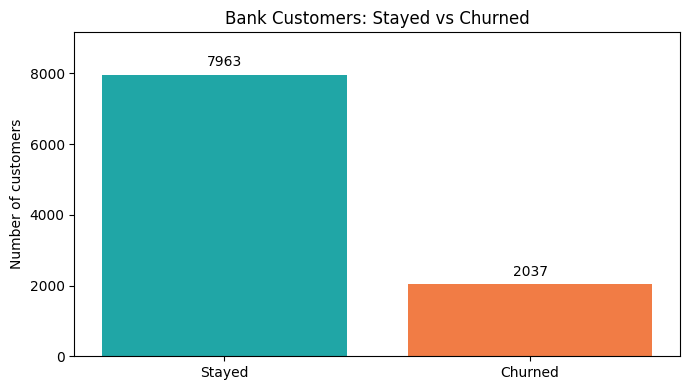

In [15]:
import matplotlib.pyplot as plt

status_counts = (
    bank_clean["Exited"]
    .map({0: "Stayed", 1: "Churned"})
    .value_counts()
    .reindex(["Stayed", "Churned"])
)

total_customers = status_counts.sum()
churned_customers = status_counts["Churned"]
churn_rate = churned_customers / total_customers * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print(f"Churn rate: {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    status_counts.index,
    status_counts.values,
    color=["#20A6A6", "#F17C45"]
)

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Bank Customers: Stayed vs Churned")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, status_counts.max() * 1.15)
plt.tight_layout()
plt.show()

,Geography,customers,churned_customers,churn_rate_pct
0,France,5014,810,16.15
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


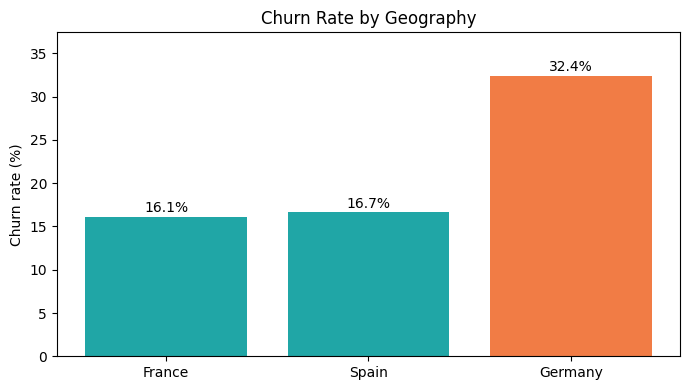

In [16]:
geography_summary = (
    bank_clean.groupby("Geography")
    .agg(
        customers=("CustomerId", "nunique"),
        churned_customers=("Exited", "sum"),
        churn_rate=("Exited", "mean")
    )
    .reset_index()
)

geography_summary["churn_rate_pct"] = (
    geography_summary["churn_rate"] * 100
).round(2)

display(geography_summary[[
    "Geography", "customers", "churned_customers", "churn_rate_pct"
]])

geography_summary = geography_summary.sort_values("churn_rate_pct")

colors = [
    "#F17C45" if rate == geography_summary["churn_rate_pct"].max()
    else "#20A6A6"
    for rate in geography_summary["churn_rate_pct"]
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    geography_summary["Geography"],
    geography_summary["churn_rate_pct"],
    color=colors
)

for bar, rate in zip(bars, geography_summary["churn_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center"
    )

ax.set_title("Churn Rate by Geography")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, geography_summary["churn_rate_pct"].max() + 5)
plt.tight_layout()
plt.show()

,AgeGroup,customers,churned_customers,churn_rate_pct
0,18-29,1641,124,7.56
1,30-39,4346,473,10.88
2,40-49,2618,806,30.79
3,50-59,869,487,56.04
4,60+,526,147,27.95


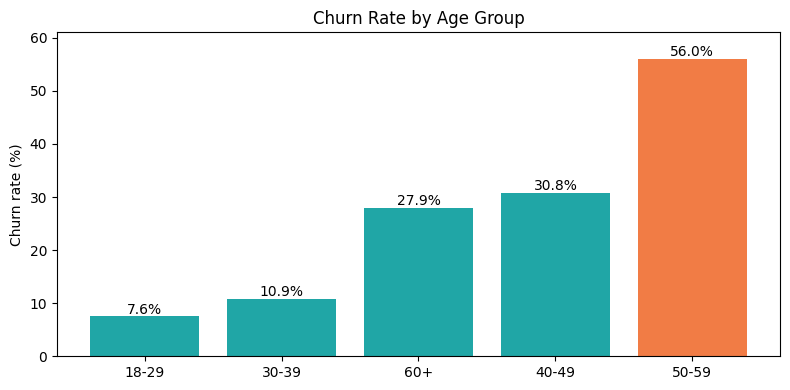

In [17]:
bank_analysis = bank_clean.copy()

bank_analysis["AgeGroup"] = pd.cut(
    bank_analysis["Age"],
    bins=[17, 29, 39, 49, 59, 120],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
)

age_summary = (
    bank_analysis.groupby("AgeGroup", observed=True)
    .agg(
        customers=("CustomerId", "nunique"),
        churned_customers=("Exited", "sum"),
        churn_rate=("Exited", "mean")
    )
    .reset_index()
)

age_summary["churn_rate_pct"] = (
    age_summary["churn_rate"] * 100
).round(2)

display(age_summary[[
    "AgeGroup", "customers", "churned_customers", "churn_rate_pct"
]])

age_summary = age_summary.sort_values("churn_rate_pct")
colors = [
    "#F17C45" if rate == age_summary["churn_rate_pct"].max()
    else "#20A6A6"
    for rate in age_summary["churn_rate_pct"]
]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    age_summary["AgeGroup"].astype(str),
    age_summary["churn_rate_pct"],
    color=colors
)

for bar, rate in zip(bars, age_summary["churn_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center"
    )

ax.set_title("Churn Rate by Age Group")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, age_summary["churn_rate_pct"].max() + 5)
plt.tight_layout()
plt.show()

,NumOfProducts,customers,churned_customers,churn_rate_pct
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


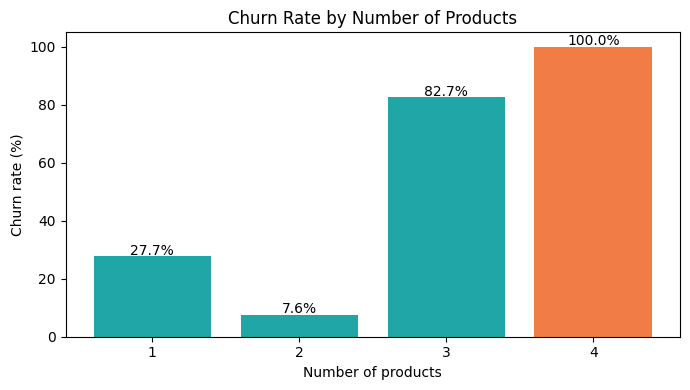

In [18]:
product_summary = (
    bank_clean.groupby("NumOfProducts")
    .agg(
        customers=("CustomerId", "nunique"),
        churned_customers=("Exited", "sum"),
        churn_rate=("Exited", "mean")
    )
    .reset_index()
)

product_summary["churn_rate_pct"] = (
    product_summary["churn_rate"] * 100
).round(2)

display(product_summary[[
    "NumOfProducts", "customers", "churned_customers", "churn_rate_pct"
]])

colors = [
    "#F17C45" if rate == product_summary["churn_rate_pct"].max()
    else "#20A6A6"
    for rate in product_summary["churn_rate_pct"]
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    product_summary["NumOfProducts"].astype(str),
    product_summary["churn_rate_pct"],
    color=colors
)

for bar, rate in zip(bars, product_summary["churn_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center"
    )

ax.set_title("Churn Rate by Number of Products")
ax.set_xlabel("Number of products")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, product_summary["churn_rate_pct"].max() + 5)
plt.tight_layout()
plt.show()

,MemberStatus,customers,churned_customers,churn_rate_pct
0,Inactive,4849,1302,26.85
1,Active,5151,735,14.27


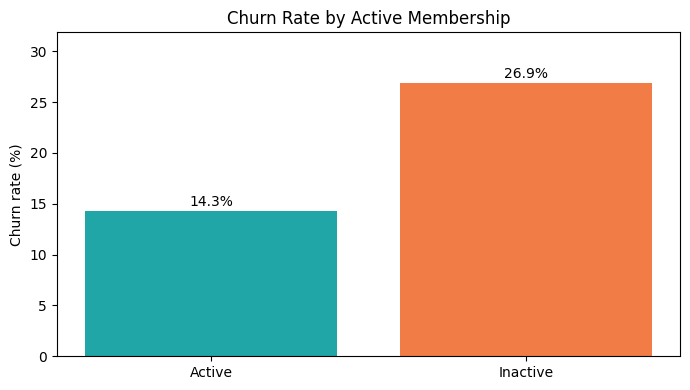

In [19]:
activity_summary = (
    bank_clean.groupby("IsActiveMember")
    .agg(
        customers=("CustomerId", "nunique"),
        churned_customers=("Exited", "sum"),
        churn_rate=("Exited", "mean")
    )
    .reset_index()
)

activity_summary["MemberStatus"] = activity_summary["IsActiveMember"].map({
    0: "Inactive",
    1: "Active"
})
activity_summary["churn_rate_pct"] = (
    activity_summary["churn_rate"] * 100
).round(2)

display(activity_summary[[
    "MemberStatus", "customers", "churned_customers", "churn_rate_pct"
]])

activity_summary = activity_summary.sort_values("churn_rate_pct")
colors = [
    "#F17C45" if rate == activity_summary["churn_rate_pct"].max()
    else "#20A6A6"
    for rate in activity_summary["churn_rate_pct"]
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    activity_summary["MemberStatus"],
    activity_summary["churn_rate_pct"],
    color=colors
)

for bar, rate in zip(bars, activity_summary["churn_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center"
    )

ax.set_title("Churn Rate by Active Membership")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, activity_summary["churn_rate_pct"].max() + 5)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

feature_columns = [
    "CreditScore",
    "Geography",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

X = bank_clean[feature_columns].copy()
y = bank_clean["Exited"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")
print("\nFeatures used:", X.columns.tolist())

Training rows: 8000
Test rows: 2000

Training churn rate: 20.38 %
Test churn rate: 20.35 %

Features used: ['CreditScore', 'Geography', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", StandardScaler(), numeric_features),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

tree_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Logistic regression trained.")
print("Decision tree trained.")

Logistic regression trained.
Decision tree trained.


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

models = {
    "Logistic regression": logistic_model,
    "Decision tree": tree_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 score": f1_score(y_test, predictions, zero_division=0),
        "True negatives": tn,
        "False positives": fp,
        "Missed churners": fn,
        "Found churners": tp
    })

model_results = pd.DataFrame(results).round(3)
display(model_results)

,Model,Accuracy,Precision,Recall,F1 score,True negatives,False positives,Missed churners,Found churners
0,Logistic regression,0.816,0.627,0.236,0.343,1536,57,311,96
1,Decision tree,0.857,0.727,0.477,0.576,1520,73,213,194


,Feature,Importance
1,Age,0.442
4,NumOfProducts,0.324
6,IsActiveMember,0.148
3,Balance,0.061
9,Geography_Germany,0.023
7,EstimatedSalary,0.002
0,CreditScore,0.000
2,Tenure,0.000
5,HasCrCard,0.000
8,Geography_France,0.000


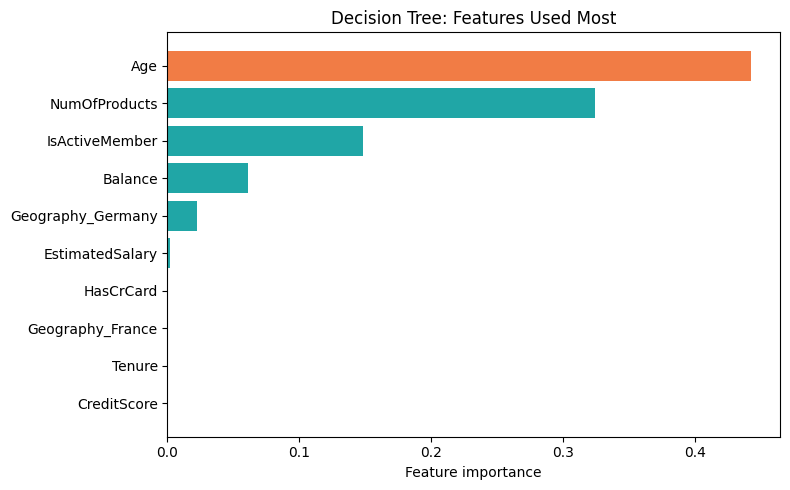

In [23]:
tree_feature_names = (
    tree_model.named_steps["preprocessing"].get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": tree_feature_names,
    "Importance": tree_model.named_steps["model"].feature_importances_
})

feature_importance["Feature"] = (
    feature_importance["Feature"]
    .str.replace("numbers__", "", regex=False)
    .str.replace("categories__", "", regex=False)
)

top_features = feature_importance.sort_values(
    "Importance", ascending=False
).head(10)

display(top_features.round(3))

plot_features = top_features.sort_values("Importance")
colors = [
    "#F17C45" if value == top_features["Importance"].max()
    else "#20A6A6"
    for value in plot_features["Importance"]
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_features["Feature"], plot_features["Importance"], color=colors)
ax.set_title("Decision Tree: Features Used Most")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [24]:
baseline_churn_rate = bank_clean["Exited"].mean()

bank_scored_test = bank_clean.loc[
    X_test.index,
    ["CustomerId", "Exited", "Geography", "Age",
     "NumOfProducts", "IsActiveMember"]
].copy()

bank_scored_test["predicted_churn_probability"] = (
    tree_model.predict_proba(X_test)[:, 1]
)

bank_scored_test["risk_band"] = pd.cut(
    bank_scored_test["predicted_churn_probability"],
    bins=[0, baseline_churn_rate, 0.5, 1.000001],
    labels=["Below average", "Moderate", "High"],
    right=False,
    include_lowest=True
)

risk_summary = (
    bank_scored_test.groupby("risk_band", observed=True)
    .agg(
        test_customers=("CustomerId", "nunique"),
        actual_churned=("Exited", "sum"),
        actual_churn_rate=("Exited", "mean"),
        average_predicted_risk=("predicted_churn_probability", "mean")
    )
    .reset_index()
)

risk_summary["actual_churn_rate_pct"] = (
    risk_summary["actual_churn_rate"] * 100
).round(2)

risk_summary["average_predicted_risk_pct"] = (
    risk_summary["average_predicted_risk"] * 100
).round(2)

display(risk_summary[[
    "risk_band", "test_customers", "actual_churned",
    "actual_churn_rate_pct", "average_predicted_risk_pct"
]])

,risk_band,test_customers,actual_churned,actual_churn_rate_pct,average_predicted_risk_pct
0,Below average,1301,92,7.07,7.14
1,Moderate,432,121,28.01,30.39
2,High,267,194,72.66,73.78


In [25]:
high_risk_customers = int(
    (bank_scored_test["risk_band"] == "High").sum()
)

offer_cost_per_customer_eur = 10.00
assumed_save_rates = [0.05, 0.10, 0.15]

offer_scenarios = []

for save_rate in assumed_save_rates:
    estimated_saves = high_risk_customers * save_rate
    total_offer_cost = high_risk_customers * offer_cost_per_customer_eur

    offer_scenarios.append({
        "Assumed retention uplift": f"{save_rate:.0%}",
        "High-risk customers targeted": high_risk_customers,
        "Estimated extra customers retained": round(estimated_saves, 1),
        "Estimated offer cost (€)": round(total_offer_cost, 2),
        "Cost per estimated extra customer (€)": round(
            total_offer_cost / estimated_saves, 2
        )
    })

offer_scenario_table = pd.DataFrame(offer_scenarios)
display(offer_scenario_table)

,Assumed retention uplift,High-risk customers targeted,Estimated extra customers retained,Estimated offer cost (€),Cost per estimated extra customer (€)
0,5%,267,13.4,2670.0,200.00
1,10%,267,26.7,2670.0,100.00
2,15%,267,40.0,2670.0,66.67


In [26]:
from google.colab import files

customer_data = bank_analysis.drop(
    columns=["Surname"],
    errors="ignore"
).copy()

test_risk_scores = bank_scored_test.copy()
test_risk_scores["predicted_churn"] = tree_model.predict(X_test)
test_risk_scores["risk_band"] = test_risk_scores["risk_band"].astype(str)

output_file = "Project3_Bank_Churn_Dashboard_Data.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    customer_data.to_excel(
        writer, sheet_name="Customer_Data", index=False
    )
    test_risk_scores.to_excel(
        writer, sheet_name="Test_Risk_Scores", index=False
    )
    model_results.to_excel(
        writer, sheet_name="Model_Metrics", index=False
    )
    offer_scenario_table.to_excel(
        writer, sheet_name="Offer_Scenarios", index=False
    )

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>